# 19 — LID scenario comparison lab

This notebook creates a small SWMM model with several subcatchments, runs a baseline model with **no LID**, then creates scenario models that add one specific LID type or a controlled combination of LIDs. It compares each scenario against the original model using time-series plots, total-runoff bars, peak-runoff bars, and percent-reduction tables.

The goal is not to replace engineering judgment. The numbers here are a compact teaching example; for design work, calibrate parameters, validate model assumptions, and review the EPA SWMM report.

## What this notebook demonstrates

- Build a sample drainage model programmatically.
- Run the original model without LIDs.
- Add one LID type per scenario: bio-retention cell, rain garden, green roof, infiltration trench, permeable pavement, rain barrel, rooftop disconnection, and vegetative swale.
- Compare scenarios that use a **single LID control** versus scenarios that use **multiple LID controls**.
- Compare one LID type with different settings, such as different `area_percent` and `initial_saturation`.
- Use `m.get.subcatchment.runoff(format="df")` for comparison plots.
- Use `m.plot_layout(annotation=...)` to visually inspect scenario geometry and assigned LIDs.

In [1]:
from pathlib import Path
import re
import sys
import warnings

# Prefer the local repository source when this notebook is run from the repo root
# or from the examples folder. This avoids accidentally using an older installed
# swmmx wheel while developing/testing new LID functionality.
_here = Path.cwd().resolve()
for _candidate in (_here / "src", _here.parent / "src"):
    if (_candidate / "swmmx").exists() and str(_candidate) not in sys.path:
        sys.path.insert(0, str(_candidate))
        break

import matplotlib.pyplot as plt
import pandas as pd

import swmmx
from swmmx import swmm

print(f"Using swmmx {swmmx.__version__} from {Path(swmmx.__file__).resolve()}")

OUTPUT_DIR = Path("output/lid_scenario_lab")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True


Using swmmx 0.0.42 from C:\Users\Mohammadali\Documents\My_Codes\swmmx_dev\src\swmmx\__init__.py


## Build the base SWMM model

The model has five subcatchments draining to a simple conduit chain. All scenarios start from the same function, so comparisons are clean: only the LID assignment changes.

In [2]:
def design_storm_timeseries():
    """Return a 6-hour synthetic design storm in 5-minute steps."""

    data = []
    for i in range(73):
        minutes = i * 5
        hour = minutes // 60
        minute = minutes % 60
        if 30 <= minutes <= 150:
            intensity = 35.0
        elif 155 <= minutes <= 210:
            intensity = 10.0
        else:
            intensity = 0.0
        data.append((f"01/01/2000 {hour:02d}:{minute:02d}", intensity))
    return data


def build_base_model():
    """Create a runnable SWMM model with subcatchments, nodes, links, and rainfall."""

    m = swmm(new="SI")
    options = {
        "FLOW_UNITS": "CMS",
        "INFILTRATION": "HORTON",
        "FLOW_ROUTING": "KINWAVE",
        "START_DATE": "01/01/2000",
        "START_TIME": "00:00:00",
        "END_DATE": "01/01/2000",
        "END_TIME": "06:00:00",
        "REPORT_START_DATE": "01/01/2000",
        "REPORT_START_TIME": "00:00:00",
        "REPORT_STEP": "00:05:00",
        "WET_STEP": "00:05:00",
        "DRY_STEP": "00:05:00",
        "ROUTING_STEP": "00:01:00",
    }
    for key, value in options.items():
        m.options[key] = value

    m.add.time.time_series("DesignStorm", data=design_storm_timeseries())
    m.add.hydrology.rain_gage(
        "RG1",
        format="INTENSITY",
        interval="00:05",
        source_type="TIMESERIES",
        time_series="DesignStorm",
        x=-40,
        y=120,
    )

    for i in range(1, 6):
        m.add.node.junction(
            f"J{i}",
            x=i * 100,
            y=0,
            invert_elevation=10 - i * 0.20,
            max_depth=4.0,
        )
    m.add.node.outfall("OUT1", x=650, y=0, invert_elevation=8.0, type="FREE")

    for i in range(1, 5):
        m.add.link.conduit(
            f"C{i}",
            from_node=f"J{i}",
            to_node=f"J{i+1}",
            roughness=0.013,
            shape="CIRCULAR",
            diameter=1.20,
        )
    m.add.link.conduit("C5", from_node="J5", to_node="OUT1", roughness=0.013, shape="CIRCULAR", diameter=1.20)

    subcatchments = [
        ("S1", "J1", 1.2, 100, 1.0, 45),
        ("S2", "J2", 1.4, 110, 1.2, 52),
        ("S3", "J3", 1.6, 120, 1.0, 60),
        ("S4", "J4", 1.8, 130, 0.9, 68),
        ("S5", "J5", 2.0, 140, 0.8, 72),
    ]
    for index, (sid, outlet, area, width, slope, impervious) in enumerate(subcatchments, start=1):
        x = index * 100
        y = 110
        polygon = [(x - 38, y - 28), (x + 38, y - 28), (x + 38, y + 28), (x - 38, y + 28)]
        m.add.hydrology.subcatchment(
            sid,
            rain_gage="RG1",
            outlet=outlet,
            x=x,
            y=y,
            area=area,
            width=width,
            slope=slope,
            impervious_percent=impervious,
            n_impervious=0.012,
            n_pervious=0.24,
            depression_storage_impervious=1.5,
            depression_storage_pervious=5.0,
            zero_depression_storage_impervious_percent=25,
            subarea_routing="OUTLET",
            percent_routed=100,
            maximum_rate=75,
            minimum_rate=3,
            decay=4,
            dry_time=7,
            maximum_volume=0,
            polygon=polygon,
        )
    return m

## Add a reusable LID control library

The function below adds one control for each EPA SWMM LID type. Scenarios can then choose one or more controls without redefining layer parameters each time.

In [3]:
def add_lid_control_library(m):
    """Add representative LID controls for all EPA SWMM LID types."""

    m.add.hydrology.lid_control(
        "BR",
        type="bio_retention_cell",
        surface={"storage_depth": 100, "vegetation_fraction": 0.20, "roughness": 0.10, "slope": 1, "side_slope": 0},
        soil={"thickness": 450, "porosity": 0.45, "field_capacity": 0.20, "wilting_point": 0.10, "conductivity": 10, "conductivity_slope": 10, "suction_head": 50},
        storage={"height": 300, "void_ratio": 0.75, "seepage_rate": 2, "clogging_factor": 0},
        drain={"coefficient": 0.50, "exponent": 0.50, "offset_height": 0, "delay": 0},
    )
    m.add.hydrology.lid_control(
        "RG",
        type="rain_garden",
        surface={"storage_depth": 80, "vegetation_fraction": 0.25, "roughness": 0.12, "slope": 1, "side_slope": 0},
        soil={"thickness": 350, "porosity": 0.43, "field_capacity": 0.18, "wilting_point": 0.08, "conductivity": 8, "conductivity_slope": 8, "suction_head": 45},
    )
    m.add.hydrology.lid_control(
        "GR",
        type="green_roof",
        surface={"storage_depth": 50, "vegetation_fraction": 0.80, "roughness": 0.20, "slope": 2, "side_slope": 0},
        soil={"thickness": 100, "porosity": 0.50, "field_capacity": 0.22, "wilting_point": 0.10, "conductivity": 6, "conductivity_slope": 6, "suction_head": 35},
        drain_mat={"thickness": 25, "void_ratio": 0.50, "roughness": 0.10},
    )
    m.add.hydrology.lid_control(
        "IT",
        type="infiltration_trench",
        surface={"storage_depth": 75, "vegetation_fraction": 0, "roughness": 0.05, "slope": 0.5, "side_slope": 0},
        storage={"height": 600, "void_ratio": 0.40, "seepage_rate": 8, "clogging_factor": 0},
    )
    m.add.hydrology.lid_control(
        "PP",
        type="permeable_pavement",
        surface={"storage_depth": 20, "vegetation_fraction": 0, "roughness": 0.015, "slope": 1, "side_slope": 0},
        pavement={"thickness": 150, "void_ratio": 0.15, "impervious_surface_fraction": 0, "permeability": 100, "clogging_factor": 0, "regeneration_interval": 0, "regeneration_fraction": 0},
        storage={"height": 300, "void_ratio": 0.40, "seepage_rate": 5, "clogging_factor": 0},
    )
    m.add.hydrology.lid_control(
        "RB",
        type="rain_barrel",
        storage={"height": 900, "void_ratio": 1.0, "seepage_rate": 0, "clogging_factor": 0, "covered": True},
        drain={"coefficient": 0.10, "exponent": 0.50, "offset_height": 50, "delay": 2},
    )
    m.add.hydrology.lid_control(
        "RD",
        type="rooftop_disconnection",
        surface={"storage_depth": 25, "vegetation_fraction": 0.10, "roughness": 0.15, "slope": 2, "side_slope": 0},
    )
    m.add.hydrology.lid_control(
        "VS",
        type="vegetative_swale",
        surface={"storage_depth": 120, "vegetation_fraction": 0.50, "roughness": 0.24, "slope": 1, "side_slope": 3},
    )
    return m

## Scenario helper functions

Each scenario starts from the base model. This avoids accidental carry-over between runs. The helper collects subcatchment runoff time series and compact metrics.

In [4]:
SUBCATCHMENTS = [f"S{i}" for i in range(1, 6)]


def slugify(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


def assign_lid_to_subcatchments(m, lid_id, subcatchments=SUBCATCHMENTS, **usage_options):
    for sid in subcatchments:
        m.set.subcatchment.lid_controls.add(sid, lid_id, **usage_options)
    return m


def collect_metrics(name, m):
    runoff = m.get.subcatchment.runoff(format="df")
    total_hydrograph = runoff.sum(axis=1).rename(name)
    return {
        "name": name,
        "model": m,
        "runoff": runoff,
        "total_hydrograph": total_hydrograph,
        "total_runoff_index_sum": float(total_hydrograph.sum()),
        "peak_runoff": float(total_hydrograph.max()),
        "mean_runoff": float(total_hydrograph.mean()),
    }


def run_scenario(name, configure=None, save_inp=True):
    m = build_base_model()
    if configure is not None:
        add_lid_control_library(m)
        configure(m)
    validation = m.validate()
    if not validation.ok:
        print(validation.to_frame())
    result = m.run()
    if not result.success:
        log = m.log()
        print(log)
        lid_rows = m.section("LID_USAGE")
        if lid_rows:
            print("\nGenerated [LID_USAGE] rows:")
            for row in lid_rows:
                print(row)
        raise RuntimeError(f"Scenario failed: {name}. See SWMM log above.")
    if save_inp:
        m.save(OUTPUT_DIR / f"{slugify(name)}.inp")
    return collect_metrics(name, m)

## Define scenarios

The first group uses exactly one LID control per scenario. The later scenarios compare a mixed LID strategy and several different settings for the same bio-retention control.

In [5]:
SCENARIOS = [
    ("Baseline — no LID", None),
    ("Single LID — Bio-retention 10%", lambda m: assign_lid_to_subcatchments(m, "BR", area_percent=10)),
    ("Single LID — Rain garden 10%", lambda m: assign_lid_to_subcatchments(m, "RG", area_percent=10)),
    ("Single LID — Green roof on high-impervious subcatchments", lambda m: assign_lid_to_subcatchments(m, "GR", subcatchments=["S3", "S4", "S5"], area_percent=12)),
    ("Single LID — Infiltration trench 10%", lambda m: assign_lid_to_subcatchments(m, "IT", area_percent=10)),
    ("Single LID — Permeable pavement 10%", lambda m: assign_lid_to_subcatchments(m, "PP", area_percent=10)),
    ("Single LID — Rain barrel 5% roof capture", lambda m: assign_lid_to_subcatchments(m, "RB", subcatchments=["S3", "S4", "S5"], area_percent=5, number=8, from_impervious_percent=40)),
    ("Single LID — Rooftop disconnection 15%", lambda m: assign_lid_to_subcatchments(m, "RD", subcatchments=["S3", "S4", "S5"], area_percent=15, from_impervious_percent=30)),
    ("Single LID — Vegetative swale 10%", lambda m: assign_lid_to_subcatchments(m, "VS", area_percent=10)),
    ("Multiple LIDs — BR 8% + PP 8% + RB 3%", lambda m: [
        assign_lid_to_subcatchments(m, "BR", area_percent=8),
        assign_lid_to_subcatchments(m, "PP", area_percent=8),
        assign_lid_to_subcatchments(m, "RB", subcatchments=["S3", "S4", "S5"], area_percent=3, number=6, from_impervious_percent=20),
    ]),
    ("BR settings — 5% area", lambda m: assign_lid_to_subcatchments(m, "BR", area_percent=5)),
    ("BR settings — 20% area", lambda m: assign_lid_to_subcatchments(m, "BR", area_percent=20)),
    ("BR settings — 20% area, initially wet", lambda m: assign_lid_to_subcatchments(m, "BR", area_percent=20, initial_saturation=80)),
    ("BR settings — 20% area, treats impervious runoff", lambda m: assign_lid_to_subcatchments(m, "BR", area_percent=20, from_impervious_percent=60)),
]

## Run all scenarios

This cell may take a little time because each scenario is a separate SWMM run.

In [6]:
results = []
for name, configure in SCENARIOS:
    print(f"Running: {name}")
    results.append(run_scenario(name, configure))

baseline = results[0]
print("Done.")

Running: Baseline — no LID
Running: Single LID — Bio-retention 10%
Running: Single LID — Rain garden 10%
Running: Single LID — Green roof on high-impervious subcatchments
Running: Single LID — Infiltration trench 10%
Running: Single LID — Permeable pavement 10%
Running: Single LID — Rain barrel 5% roof capture
Running: Single LID — Rooftop disconnection 15%
Running: Single LID — Vegetative swale 10%
Running: Multiple LIDs — BR 8% + PP 8% + RB 3%
Running: BR settings — 5% area
Running: BR settings — 20% area
Running: BR settings — 20% area, initially wet
Running: BR settings — 20% area, treats impervious runoff
Done.


## Inspect one scenario layout

The plot uses annotations to show subcatchment IDs and assigned LID labels. You can change the index to inspect any scenario.

(<Figure size 3000x2400 with 1 Axes>, <Axes: >)

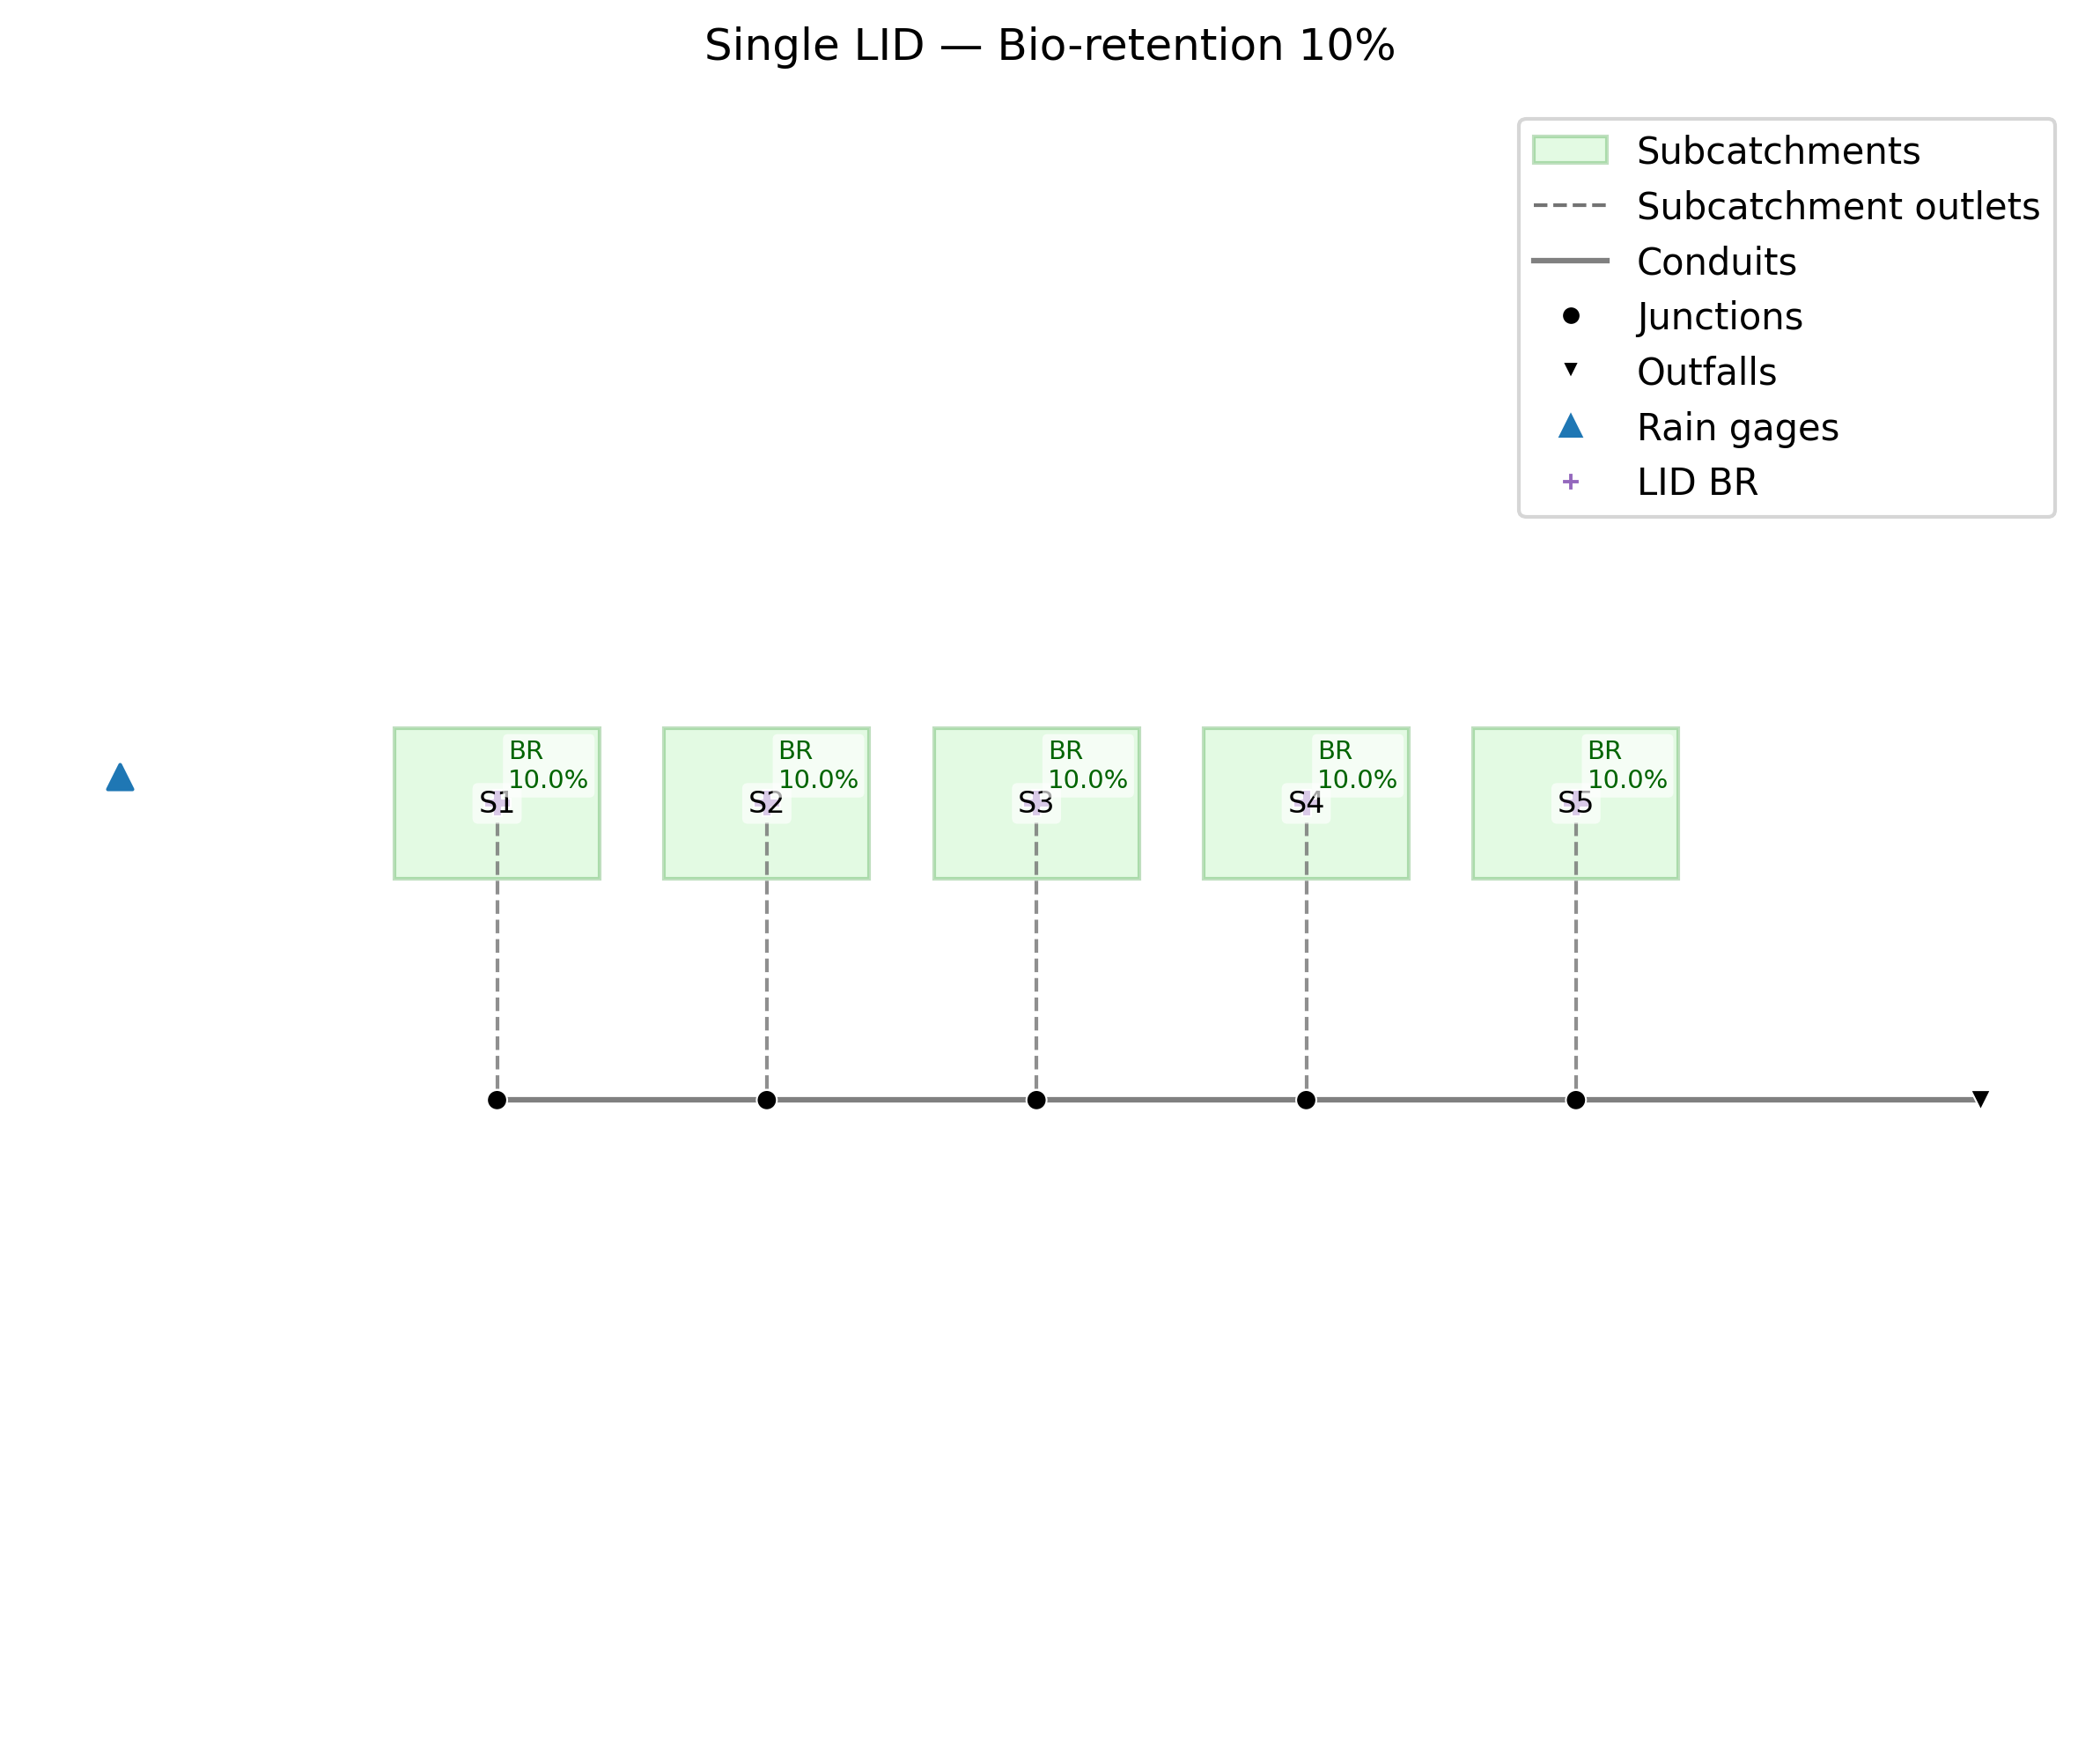

In [7]:
scenario_to_view = results[1]  # Bio-retention 10%
scenario_to_view["model"].plot_layout(
    title=scenario_to_view["name"],
    annotation={
        "subcatchments": {"template": "{id}", "fontsize": 8, "bbox": True},
        "lid_usages": {"template": "{lid_control}\n{area_percent:.1f}%", "fontsize": 7, "color": "darkgreen", "bbox": True},
    },
)

## Compare total runoff hydrographs

The total hydrograph below sums runoff over all subcatchments for each scenario. This makes the comparison easy to read, while later cells show subcatchment-level behavior.

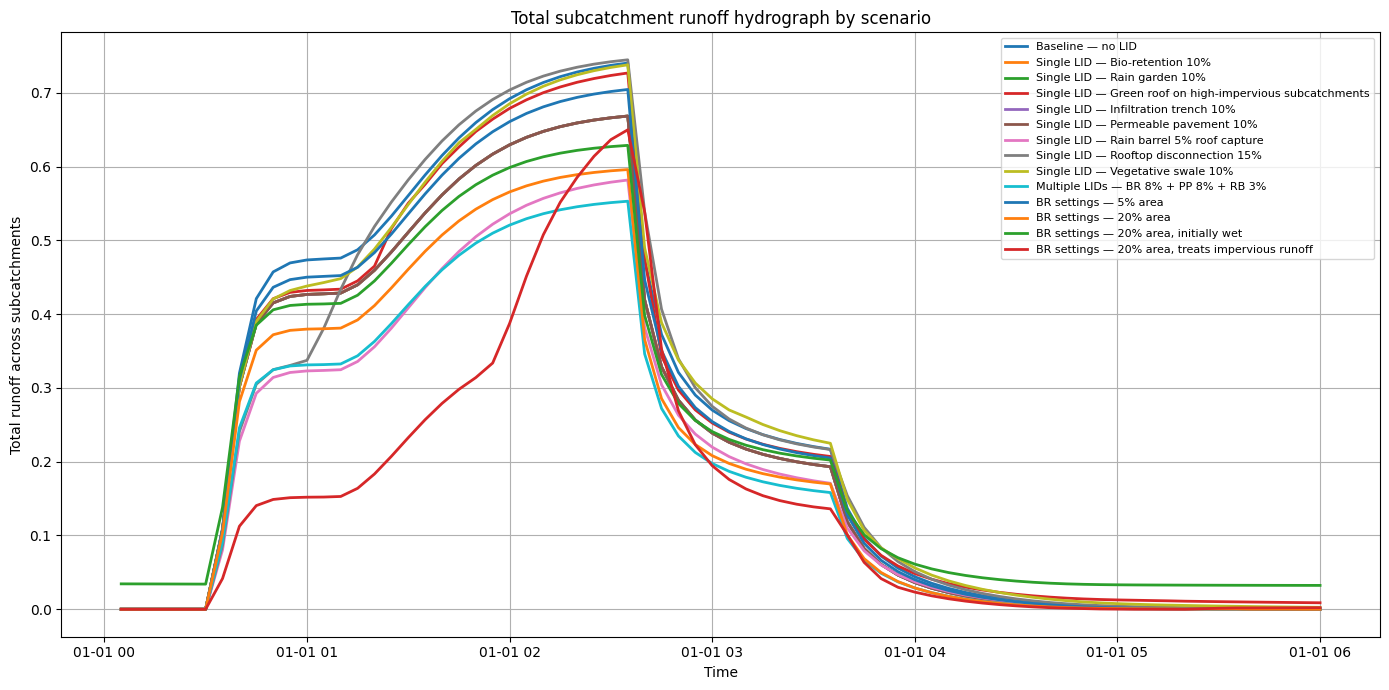

In [8]:
hydrographs = pd.concat([r["total_hydrograph"] for r in results], axis=1)

fig, ax = plt.subplots(figsize=(14, 7))
for column in hydrographs.columns:
    ax.plot(hydrographs.index, hydrographs[column], linewidth=2, label=column)
ax.set_title("Total subcatchment runoff hydrograph by scenario")
ax.set_xlabel("Time")
ax.set_ylabel("Total runoff across subcatchments")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()


## Total and peak runoff reductions

These metrics compare every scenario against the original model without LID. The `total_runoff_index_sum` is a compact comparative index from the time-series output; use model reports and calibrated unit workflows for engineering design quantities.

In [9]:
metrics = pd.DataFrame(
    {
        "scenario": [r["name"] for r in results],
        "total_runoff_index_sum": [r["total_runoff_index_sum"] for r in results],
        "peak_runoff": [r["peak_runoff"] for r in results],
        "mean_runoff": [r["mean_runoff"] for r in results],
    }
).set_index("scenario")

base_total = metrics.loc["Baseline — no LID", "total_runoff_index_sum"]
base_peak = metrics.loc["Baseline — no LID", "peak_runoff"]
metrics["total_reduction_%"] = (base_total - metrics["total_runoff_index_sum"]) / base_total * 100
metrics["peak_reduction_%"] = (base_peak - metrics["peak_runoff"]) / base_peak * 100
metrics.round(2)

,total_runoff_index_sum,peak_runoff,mean_runoff,total_reduction_%,peak_reduction_%
scenario,,,,,
Baseline — no LID,18.18,0.74,0.25,0.00,0.00
Single LID — Bio-retention 10%,16.39,0.67,0.23,9.82,9.70
Single LID — Rain garden 10%,16.39,0.67,0.23,9.82,9.70
Single LID — Green roof on high-impervious subcatchments,17.69,0.73,0.25,2.67,1.82
Single LID — Infiltration trench 10%,16.39,0.67,0.23,9.82,9.70
Single LID — Permeable pavement 10%,16.39,0.67,0.23,9.82,9.70
Single LID — Rain barrel 5% roof capture,13.80,0.58,0.19,24.09,21.42
Single LID — Rooftop disconnection 15%,17.85,0.74,0.25,1.81,-0.59
Single LID — Vegetative swale 10%,18.17,0.74,0.25,0.05,0.33


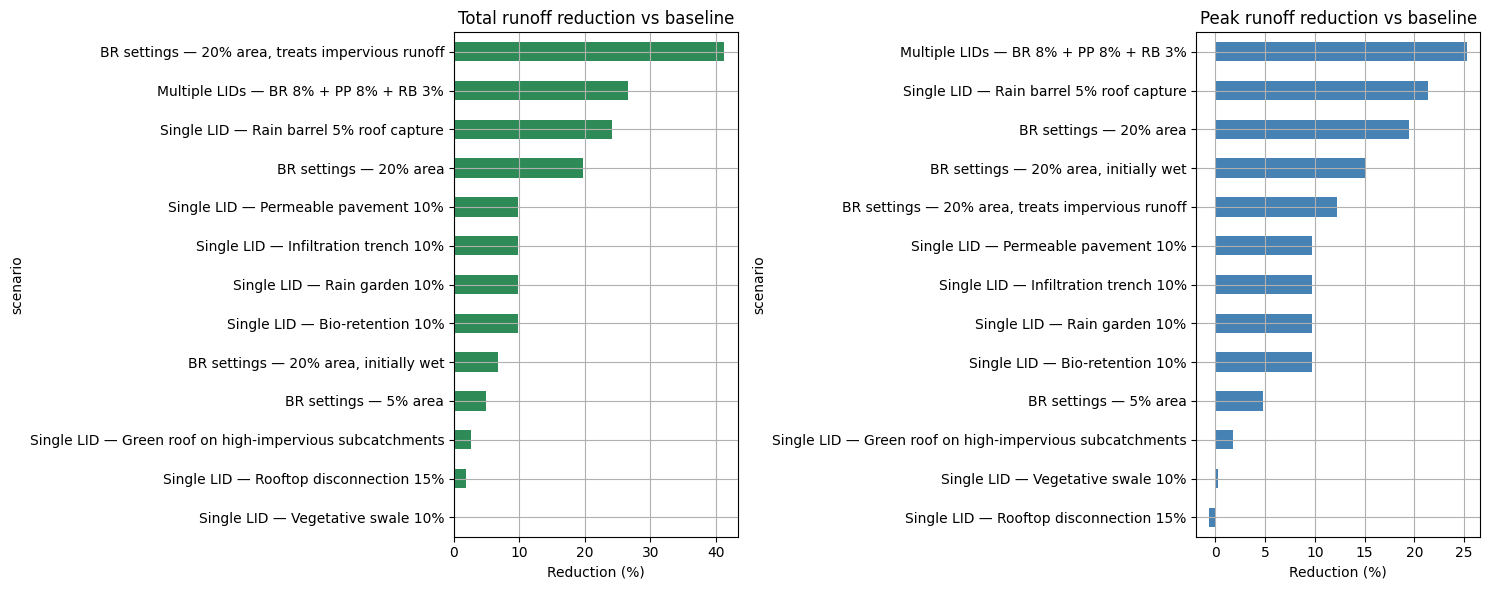

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
baseline_name = baseline["name"]

metrics["total_reduction_%"].drop(baseline_name).sort_values().plot(
    kind="barh",
    ax=axes[0],
    color="seagreen",
)
axes[0].set_title("Total runoff reduction vs baseline")
axes[0].set_xlabel("Reduction (%)")

metrics["peak_reduction_%"].drop(baseline_name).sort_values().plot(
    kind="barh",
    ax=axes[1],
    color="steelblue",
)
axes[1].set_title("Peak runoff reduction vs baseline")
axes[1].set_xlabel("Reduction (%)")
plt.tight_layout()


## Compare single-LID scenarios only

This view removes the mixed-LID and settings-sensitivity scenarios so the LID types can be compared more directly.

In [11]:
single_lid_metrics = metrics[metrics.index.str.startswith("Single LID")].copy()
single_lid_metrics.round(2)


,total_runoff_index_sum,peak_runoff,mean_runoff,total_reduction_%,peak_reduction_%
scenario,,,,,
Single LID — Bio-retention 10%,16.39,0.67,0.23,9.82,9.70
Single LID — Rain garden 10%,16.39,0.67,0.23,9.82,9.70
Single LID — Green roof on high-impervious subcatchments,17.69,0.73,0.25,2.67,1.82
Single LID — Infiltration trench 10%,16.39,0.67,0.23,9.82,9.70
Single LID — Permeable pavement 10%,16.39,0.67,0.23,9.82,9.70
Single LID — Rain barrel 5% roof capture,13.80,0.58,0.19,24.09,21.42
Single LID — Rooftop disconnection 15%,17.85,0.74,0.25,1.81,-0.59
Single LID — Vegetative swale 10%,18.17,0.74,0.25,0.05,0.33


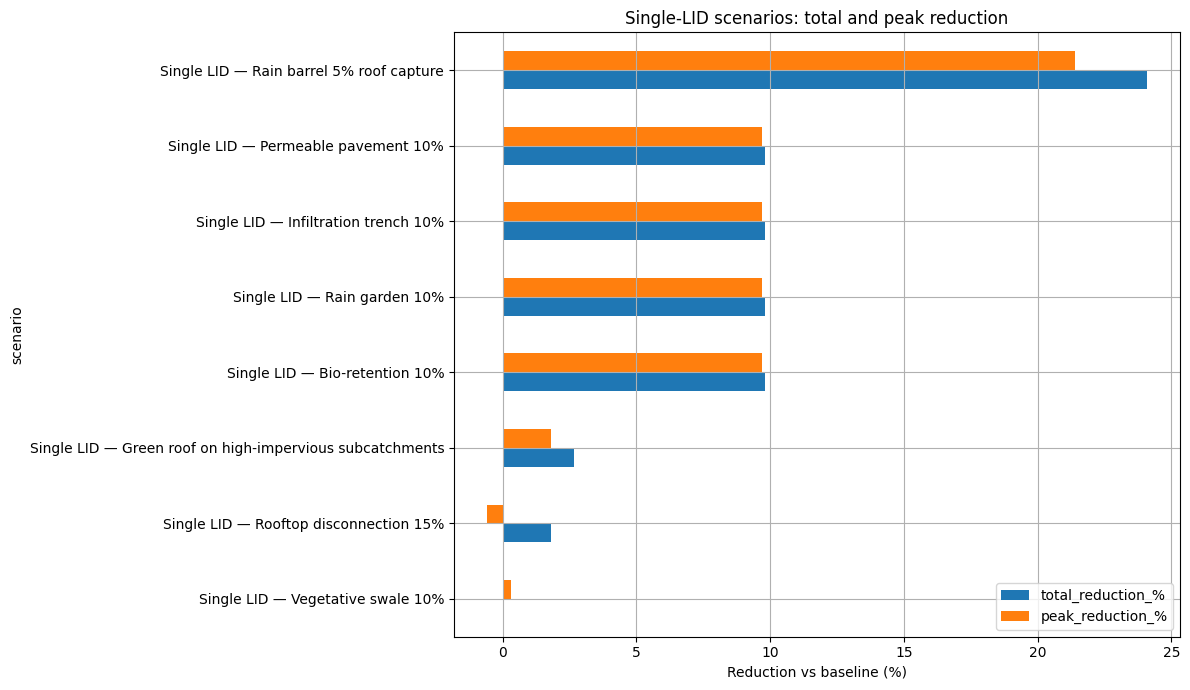

In [12]:
ax = single_lid_metrics[["total_reduction_%", "peak_reduction_%"]].sort_values("total_reduction_%").plot(
    kind="barh",
    figsize=(12, 7),
)
ax.set_title("Single-LID scenarios: total and peak reduction")
ax.set_xlabel("Reduction vs baseline (%)")
plt.tight_layout()


## Compare one LID with different settings

These scenarios all use bio-retention, but change `area_percent`, initial saturation, and how much impervious runoff is routed to the LID.

In [13]:
br_metrics = metrics[metrics.index.str.startswith("BR settings") | (metrics.index == "Single LID — Bio-retention 10%")].copy()
br_metrics[["total_runoff_index_sum", "peak_runoff", "total_reduction_%", "peak_reduction_%"]].round(2)

,total_runoff_index_sum,peak_runoff,total_reduction_%,peak_reduction_%
scenario,,,,
Single LID — Bio-retention 10%,16.39,0.67,9.82,9.70
BR settings — 5% area,17.29,0.70,4.91,4.84
BR settings — 20% area,14.60,0.60,19.68,19.50
"BR settings — 20% area, initially wet",16.97,0.63,6.67,15.07
"BR settings — 20% area, treats impervious runoff",10.69,0.65,41.22,12.22


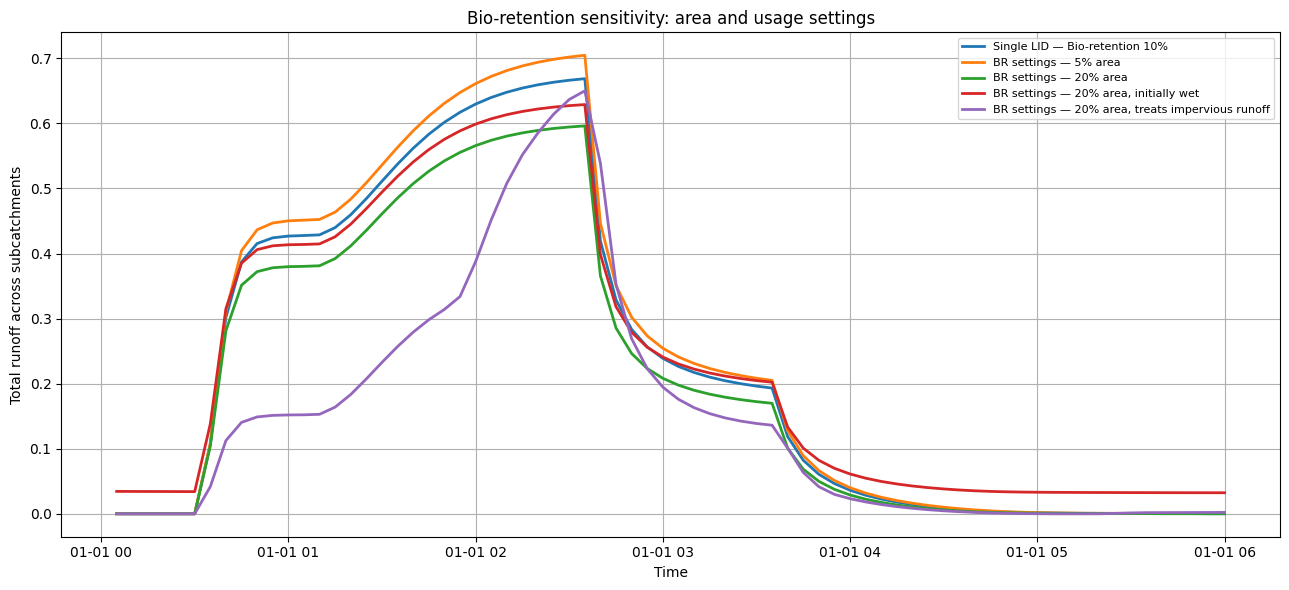

In [14]:
br_columns = [
    "Single LID — Bio-retention 10%",
    "BR settings — 5% area",
    "BR settings — 20% area",
    "BR settings — 20% area, initially wet",
    "BR settings — 20% area, treats impervious runoff",
]
br_hydrographs = hydrographs[[name for name in br_columns if name in hydrographs.columns]]

fig, ax = plt.subplots(figsize=(13, 6))
for column in br_hydrographs.columns:
    ax.plot(br_hydrographs.index, br_hydrographs[column], linewidth=2, label=column)
ax.set_title("Bio-retention sensitivity: area and usage settings")
ax.set_xlabel("Time")
ax.set_ylabel("Total runoff across subcatchments")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()


## Subcatchment-level comparison

This heatmap-style table shows the percent reduction in total runoff per subcatchment. It helps reveal where LIDs are active and where they have little direct effect.

In [15]:
baseline_sub_totals = baseline["runoff"].sum(axis=0)
subcatchment_reductions = {}
for r in results[1:]:
    scenario_totals = r["runoff"].sum(axis=0)
    subcatchment_reductions[r["name"]] = (baseline_sub_totals - scenario_totals) / baseline_sub_totals * 100
subcatchment_reductions = pd.DataFrame(subcatchment_reductions).T
subcatchment_reductions.round(2)

,S1,S2,S3,S4,S5
Single LID — Bio-retention 10%,9.70,9.77,9.82,9.87,9.88
Single LID — Rain garden 10%,9.70,9.77,9.82,9.87,9.88
Single LID — Green roof on high-impervious subcatchments,0.00,0.00,3.45,3.89,4.09
Single LID — Infiltration trench 10%,9.70,9.77,9.82,9.87,9.88
Single LID — Permeable pavement 10%,9.70,9.77,9.82,9.87,9.88
Single LID — Rain barrel 5% roof capture,0.00,0.00,32.44,34.82,35.96
Single LID — Rooftop disconnection 15%,0.00,0.00,2.05,2.67,2.95
Single LID — Vegetative swale 10%,-0.41,-0.16,0.03,0.21,0.29
Multiple LIDs — BR 8% + PP 8% + RB 3%,15.54,15.65,30.42,31.51,32.02
BR settings — 5% area,4.84,4.88,4.90,4.93,4.94


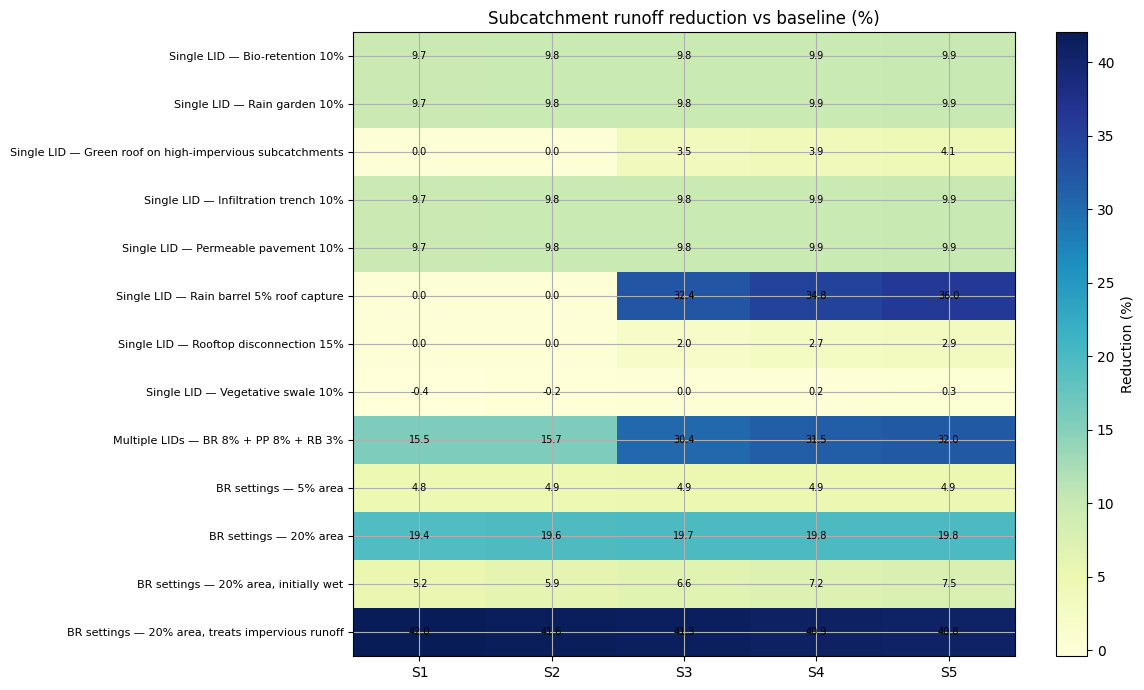

In [16]:
fig, ax = plt.subplots(figsize=(12, 7))
image = ax.imshow(subcatchment_reductions.values, aspect="auto", cmap="YlGnBu")
ax.set_xticks(range(len(subcatchment_reductions.columns)))
ax.set_xticklabels(subcatchment_reductions.columns)
ax.set_yticks(range(len(subcatchment_reductions.index)))
ax.set_yticklabels(subcatchment_reductions.index, fontsize=8)
ax.set_title("Subcatchment runoff reduction vs baseline (%)")
for i in range(subcatchment_reductions.shape[0]):
    for j in range(subcatchment_reductions.shape[1]):
        ax.text(j, i, f"{subcatchment_reductions.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="Reduction (%)")
plt.tight_layout()

## LID usage tables for auditability

This confirms exactly which LID usage rows were added in each scenario.

In [17]:
for r in results[1:4]:
    print("\n", r["name"])
    display(r["model"].get.subcatchment.lid_controls(format="df"))


 Single LID — Bio-retention 10%


,subcatchment,lid_control,number,area,width,initial_saturation,from_impervious_percent,return_flow_to_pervious,report_file,drain_to,from_pervious_percent,area_percent,occupies_full_subcatchment
0,S1,BR,1,1200,34.641016,0,0,False,None,None,0,10.0,False
1,S2,BR,1,1400,37.416574,0,0,False,None,None,0,10.0,False
2,S3,BR,1,1600,40.000000,0,0,False,None,None,0,10.0,False
3,S4,BR,1,1800,42.426407,0,0,False,None,None,0,10.0,False
4,S5,BR,1,2000,44.721360,0,0,False,None,None,0,10.0,False



 Single LID — Rain garden 10%


,subcatchment,lid_control,number,area,width,initial_saturation,from_impervious_percent,return_flow_to_pervious,report_file,drain_to,from_pervious_percent,area_percent,occupies_full_subcatchment
0,S1,RG,1,1200,34.641016,0,0,False,None,None,0,10.0,False
1,S2,RG,1,1400,37.416574,0,0,False,None,None,0,10.0,False
2,S3,RG,1,1600,40.000000,0,0,False,None,None,0,10.0,False
3,S4,RG,1,1800,42.426407,0,0,False,None,None,0,10.0,False
4,S5,RG,1,2000,44.721360,0,0,False,None,None,0,10.0,False



 Single LID — Green roof on high-impervious subcatchments


,subcatchment,lid_control,number,area,width,initial_saturation,from_impervious_percent,return_flow_to_pervious,report_file,drain_to,from_pervious_percent,area_percent,occupies_full_subcatchment
0,S3,GR,1,1920,43.817805,0,0,False,None,None,0,12.0,False
1,S4,GR,1,2160,46.475800,0,0,False,None,None,0,12.0,False
2,S5,GR,1,2400,48.989795,0,0,False,None,None,0,12.0,False


## Save comparison outputs

The notebook already saved scenario `.inp` files into `output/lid_scenario_lab/`. The cells below save the metrics tables as CSV for reporting.

In [18]:
metrics.to_csv(OUTPUT_DIR / "lid_scenario_metrics.csv")
subcatchment_reductions.to_csv(OUTPUT_DIR / "subcatchment_reduction_percent.csv")
print(f"Saved outputs to: {OUTPUT_DIR.resolve()}")

Saved outputs to: C:\Users\Mohammadali\Documents\My_Codes\swmmx_dev\examples\output\lid_scenario_lab


## Practical notes

- A LID **control** describes the device layers: surface, soil, storage, pavement, drain, drain mat, and pollutant removals where applicable.
- A subcatchment LID **usage** describes placement: number of units, area, width, initial saturation, impervious/pervious area treated, report file, drain target, and whether outflow returns to pervious area.
- For scenario work, keep one clean baseline and clone/rebuild from it for each scenario. That keeps comparisons honest.
- For real projects, calibrate hydrology, confirm units, validate detailed SWMM reports, and use engineering judgment before making design decisions.